#### Notebook for comparing the cnoidal waves with the waves from the Newton solver

In [45]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [46]:
from camera.camera_file import Camera
from camera.spectralCamera import KdVNewton
from camera.pdeCamera import KdV
from solvers.help import *
from waves.soliton import kdv_cnoidal


import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.special import ellipj, ellipk, ellipe
from scipy.optimize import brentq

In [47]:
# Wave parameters

N = 2**7
amp = 1
mean = 0
P = 20
c1 = Camera(P,N,1)

In [48]:
#Creating a newton wave
wp = KdVNewton(P,amp, mean, c1)
wp.solve_w_continuation()
phi_newton = wp.get_physical(wp.phi_hat_mid)

In [49]:
# then the cnoidal wave

phi_cn, c_cn, m = kdv_cnoidal(
    P = wp.P,
    crest=amp, 
    mean = mean,
    x = c1.x,
    t=0
)

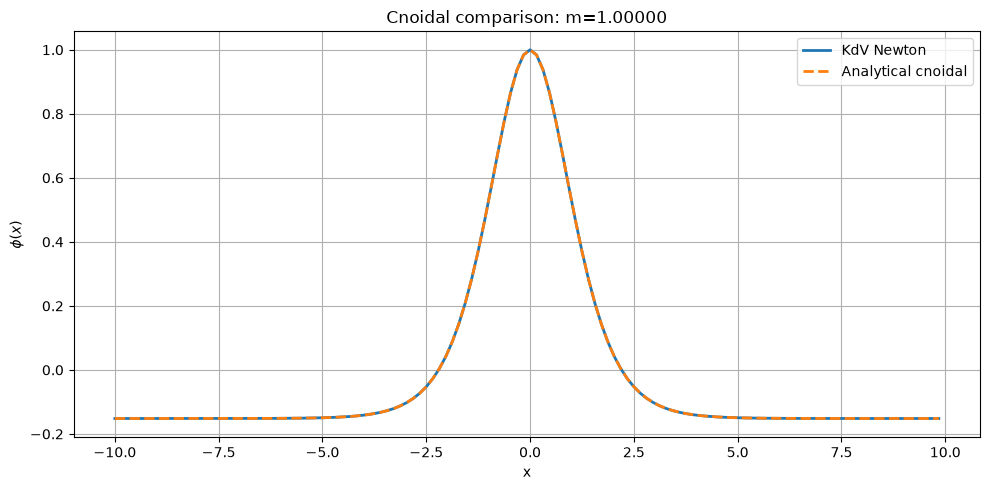

Newton wave speed:    1.2321503541
Cnoidal wave speed:   1.2321503528
Maximum profile error: 4.822e-09
RMS profile error:     1.200e-09


In [50]:
# Plotting them
plt.figure(figsize=(10, 5))
plt.plot(c1.x, phi_newton, label="KdV Newton", linewidth=2)
plt.plot(c1.x, phi_cn[0], "--", label="Analytical cnoidal", linewidth=2)
plt.xlabel("x")
plt.ylabel(r"$\phi(x)$")
plt.title(f"Cnoidal comparison: m={m:.5f}")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Newton wave speed:    {wp.c:.10f}")
print(f"Cnoidal wave speed:   {c_cn:.10f}")
print(f"Maximum profile error: "
      f"{np.max(np.abs(phi_newton - phi_cn)):.3e}")
print(f"RMS profile error:     "
      f"{np.sqrt(np.mean((phi_newton - phi_cn)**2)):.3e}")

We can then look at the forward solver and compare it to the analytical cnoidal wave

In [57]:
# Wave parameters
P = 16
N = 2**7
dt = 2e-3

c2 = Camera(P,N,dt)

T = 1
amp = 1
mean = 0

In [58]:
# Newton wave and solver
nw = KdVNewton(P,amp,mean,c2)
nw.solve_w_continuation()
nw_phi = nw.get_physical(nw.phi_hat_mid)

ns = KdV(c2, T, u0=nw_phi)
t,ns_phi = ns.ifrk4()

In [59]:
# Cnoidal wave
cn_phi, c_cn, m = kdv_cnoidal(P, amp, mean,c2.x,t)

In [60]:
# animate_solution_nb(c2.x, ns_phi)

In [61]:
# animate_solution_nb(c2.x, cn_phi)

In [62]:
animate_solution_nb(c2.x, cn_phi - ns_phi)

As we can see from the plots, the numerical solver and the analytical cn wave give similar values over the time steps. 

However, we can see that there is some radiation in the numerical sovler, the sacale is small and can be neglected. 

In comparing the split step solver with the ifrk4 one finds that the latter has an error 1e-4 lower than SS. at dt = 1e-3

Values of N greater than 2**7 does not seem to improve the errors, might hit the Newton limit. 
- Changing newton limit from 1e-13 to 1e-15 did not impact the limit in N

Values of dt greater than 1e-3 gives fluctuations in the error, for 1e-3 it is smooth and looks like radiation from KdV